# Logistic Regression on the Breast Cancer Wisconsin (Diagnostic) dataset
**Session 3: From Numbers to Decisions**

This notebook is the hands-on part of the session.

| Step | Name | Slides it applies |
|---|---|---|
| 1 | Explore data | Breast Cancer Wisconsin (Diagnostic) |
| 2 | Preprocess & scale | The pipeline (split BEFORE scaling) |
| 3 | Train / test split | The pipeline (`stratify=y`) |
| 4 | Train model | Linear combination, sigmoid, log loss, gradient descent, regularization L1/L2 |
| 5 | Predict probabilities | Sigmoid, probability interpretation |
| 6 | Apply threshold | Decision threshold, decision boundary |
| 7 | Evaluate metrics | Confusion matrix, accuracy, precision, recall, F1, ROC curve and AUC |
| 8 | Interpret coefficients | Weights w and their sign |

- the *positive class* is **malignant = 1**, and benign = 0.
- Dataset: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

In [1]:

import warnings
warnings.filterwarnings("ignore")   # hide version warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Display settings: show ALL rows and columns of every table
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 4)



---
# Step 1 · Explore data
## 1.1 Load the dataset
`load_breast_cancer(as_frame=True)` returns the data as pandas objects: `data` (the features) and `target` (the labels).

In [2]:
from sklearn.datasets import load_breast_cancer
bunch = load_breast_cancer(as_frame=True)

X_raw = bunch.data
y_raw = bunch.target

print("Shape of X_raw:", X_raw.shape)
print("Shape of y_raw:", y_raw.shape)

Shape of X_raw: (569, 30)
Shape of y_raw: (569,)


## 1.2 The 30 features: 10 measures x 3 statistics
The data comes from a **fine needle aspirate (FNA)**: cells are taken with a thin needle, an image is digitized and a program measures the **cell nuclei**. Ten measures are computed for each nucleus, and for each one three statistics are stored:
- **mean**: the average value,
- **standard error** : the variation of the value,
- **worst**: the mean of the three largest values.

So `mean radius`, `radius error` and `worst radius` describe the same measure (radius) summarized in three ways.

| # | feature (column name) | statistic | measure | meaning |
|---|---|---|---|---|
| 1 | mean radius | mean | radius | Mean distance from the center of the nucleus to points on its perimeter |
| 2 | mean texture | mean | texture | Standard deviation of gray-scale values (how uneven the brightness is) |
| 3 | mean perimeter | mean | perimeter | Length of the outline of the nucleus |
| 4 | mean area | mean | area | Surface covered by the nucleus |
| 5 | mean smoothness | mean | smoothness | Local variation in radius lengths (low = smooth outline) |
| 6 | mean compactness | mean | compactness | perimeter² / area − 1.0 (how 'tight' the shape is) |
| 7 | mean concavity | mean | concavity | Severity of concave portions (inward dents) of the contour |
| 8 | mean concave points | mean | concave points | Number of concave portions of the contour |
| 9 | mean symmetry | mean | symmetry | How symmetric the nucleus shape is |
| 10 | mean fractal dimension | mean | fractal dimension | 'Coastline approximation' − 1 (how rough the border is) |
| 11 | radius error | standard error | radius | Mean distance from the center of the nucleus to points on its perimeter |
| 12 | texture error | standard error | texture | Standard deviation of gray-scale values (how uneven the brightness is) |
| 13 | perimeter error | standard error | perimeter | Length of the outline of the nucleus |
| 14 | area error | standard error | area | Surface covered by the nucleus |
| 15 | smoothness error | standard error | smoothness | Local variation in radius lengths (low = smooth outline) |
| 16 | compactness error | standard error | compactness | perimeter² / area − 1.0 (how 'tight' the shape is) |
| 17 | concavity error | standard error | concavity | Severity of concave portions (inward dents) of the contour |
| 18 | concave points error | standard error | concave points | Number of concave portions of the contour |
| 19 | symmetry error | standard error | symmetry | How symmetric the nucleus shape is |
| 20 | fractal dimension error | standard error | fractal dimension | 'Coastline approximation' − 1 (how rough the border is) |
| 21 | worst radius | worst | radius | Mean distance from the center of the nucleus to points on its perimeter |
| 22 | worst texture | worst | texture | Standard deviation of gray-scale values (how uneven the brightness is) |
| 23 | worst perimeter | worst | perimeter | Length of the outline of the nucleus |
| 24 | worst area | worst | area | Surface covered by the nucleus |
| 25 | worst smoothness | worst | smoothness | Local variation in radius lengths (low = smooth outline) |
| 26 | worst compactness | worst | compactness | perimeter² / area − 1.0 (how 'tight' the shape is) |
| 27 | worst concavity | worst | concavity | Severity of concave portions (inward dents) of the contour |
| 28 | worst concave points | worst | concave points | Number of concave portions of the contour |
| 29 | worst symmetry | worst | symmetry | How symmetric the nucleus shape is |
| 30 | worst fractal dimension | worst | fractal dimension | 'Coastline approximation' − 1 (how rough the border is) |

## 1.3 The target (label) and the class distribution
In scikit-learn, the raw target is **0 = malignant** and **1 = benign**. We will flip it in Step 2 so that malignant = 1.

Raw coding: {0: np.str_('malignant'), 1: np.str_('benign')} (0 = malignant, 1 = benign)

Malignant: 212 | Benign: 357
Share of malignant: 37.3% (slightly imbalanced)


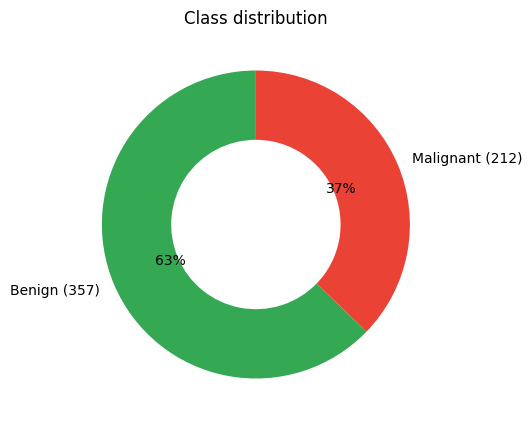

In [3]:
print("Raw coding:", dict(enumerate(bunch.target_names)), "(0 = malignant, 1 = benign)\n")

n_malignant = int((y_raw == 0).sum())
n_benign    = int((y_raw == 1).sum())
print("Malignant:", n_malignant, "| Benign:", n_benign)
print(f"Share of malignant: {n_malignant / len(y_raw):.1%} (slightly imbalanced)")

plt.figure(figsize=(5, 5))
plt.pie([n_benign, n_malignant], labels=[f"Benign ({n_benign})", f"Malignant ({n_malignant})"],
        colors=["#34A853", "#EA4335"], autopct="%1.0f%%", startangle=90,
        wedgeprops={"width": 0.45})
plt.title("Class distribution")
plt.show()

## 1.4 First rows, data types and missing values
`head()` shows the first 5 patients. Notice that features have **very different scales** (area is in hundreds, smoothness is below 1).

In [4]:
X_raw.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.589,153.40,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.398,74.08,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.585,94.03,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.445,27.23,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.438,94.44,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


In [5]:
X_raw.info()
print("\nTotal missing values:", int(X_raw.isna().sum().sum()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

**Result:** all 30 features are numeric and there are **no missing values**, so no cleaning is needed.

---
# Step 2 · Preprocess & scale
## 2.1 Build X and y (malignant = 1)
We keep the 30 features as X and **flip the target** so that **1 = malignant** (positive class). The model output `p` will then be **P(malignant)**.

In [6]:
X = X_raw.copy()
y = (y_raw == 0).astype(int)           # flip: 1 = malignant, 0 = benign
y.name = "malignant"

print("X shape:", X.shape)
print(y.value_counts().rename({1: "malignant (1)", 0: "benign (0)"}))

X shape: (569, 30)
malignant
benign (0)       357
malignant (1)    212
Name: count, dtype: int64


## 2.2 Why we scale
Gradient descent converges badly when one feature is in the thousands (`area`) and another below 1 (`smoothness`), and the weights cannot be compared with each other. The **StandardScaler** transforms each feature with `(x - mean) / std`.

> **split BEFORE scaling.** The mean and std must be computed on the **training set only**. Otherwise information from the test set leaks into the training (*data leakage*). So the scaling is *applied* in Step 3.1, right after the split.

---
# Step 3 · Train / test split
We keep 20% of the patients as a **test set** that the model never sees during training. We use `stratify=y` so that train and test keep the same proportion of malignant cases.

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Train set:", X_train.shape, "| Test set:", X_test.shape)
print(f"Malignant share in train: {y_train.mean():.1%}")
print(f"Malignant share in test : {y_test.mean():.1%}")

Train set: (455, 30) | Test set: (114, 30)
Malignant share in train: 37.4%
Malignant share in test : 36.8%


## 3.1 Apply the scaling (fit on the training set only)
- `fit` learns the mean and std **from the training data**.
- `transform` applies them to the training set **and** the test set.

In [8]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)                          # mean/std learned from TRAIN only

X_train_s = scaler.transform(X_train)        # scaled training data (NumPy array)
X_test_s  = scaler.transform(X_test)         # test data scaled with TRAIN statistics

# Check: scaled training features have mean ~0 and std ~1
pd.DataFrame({"mean": X_train_s.mean(axis=0),
              "std":  X_train_s.std(axis=0)}, index=X.columns)

,mean,std
mean radius,-1.7373e-16,1.0
mean texture,3.9041e-16,1.0
mean perimeter,4.7044e-16,1.0
mean area,-1.1712e-16,1.0
mean smoothness,7.2421e-16,1.0
mean compactness,-5.0753e-17,1.0
mean concavity,-4.4897e-17,1.0
mean concave points,2.9281e-17,1.0
mean symmetry,2.3424e-17,1.0
mean fractal dimension,3.6698e-16,1.0


---
# Step 4 · Train model

**z = w0 + w1·x1 + ... + w30·x30**  then  **p = sigma(z) = 1 / (1 + e^(-z))**


## 4.1 Fit the model with scikit-learn
Main hyperparameters:
- `penalty`: the regularization type (default "l2", see 4.2),
- `C=1.0`: the inverse of the regularization strength (**C = 1 / lambda**, small C = strong regularization),
- `max_iter=1000`: maximum number of optimizer iterations.


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (log_loss)
model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
model.fit(X_train_s, y_train)

print("Classes learned     :", model.classes_, "(1 = malignant)")
print("Iterations used     :", model.n_iter_[0])
print("Bias (intercept) w0 :", round(model.intercept_[0], 4))
print("Number of weights   :", model.coef_.shape[1])
print("Log loss on the training set:", round(log_loss(y_train, model.predict_proba(X_train_s)), 4))

Classes learned     : [0 1] (1 = malignant)
Iterations used     : 20
Bias (intercept) w0 : -0.243
Number of weights   : 30
Log loss on the training set: 0.0532


## 4.2 Regularization: L1 and L2
Regularization adds a penalty on the weights to the loss: `J_reg = LogLoss + lambda·penalty(w)`.
- **L2 (Ridge)**: penalty = Σ wj^2 -> shrinks all weights smoothly (default).
- **L1 (Lasso)**: penalty = Σ |wj| -> sets some weights **exactly to 0** (automatic feature selection).

In scikit-learn `C = 1/lambda`. The table compares both types for several values of C.

In [10]:
from sklearn.metrics import recall_score, accuracy_score
rows = []
for penalty in ["l1", "l2"]:
    for C in [0.01, 0.1, 1, 10, 100]:
        m = LogisticRegression(penalty=penalty, C=C, solver="liblinear", max_iter=1000)
        m.fit(X_train_s, y_train)
        rows.append({"penalty": penalty.upper(), "C": C,
                     "non-zero weights": int(np.sum(m.coef_[0] != 0)),
                     "test accuracy": accuracy_score(y_test, m.predict(X_test_s)),
                     "test recall": recall_score(y_test, m.predict(X_test_s))})
pd.DataFrame(rows)

,penalty,C,non-zero weights,test accuracy,test recall
0,L1,0.01,4,0.9737,1.0000
1,L1,0.10,7,0.9825,0.9524
2,L1,1.00,14,0.9737,0.9524
3,L1,10.00,21,0.9561,0.9048
4,L1,100.00,24,0.9211,0.8810
5,L2,0.01,30,0.9649,0.9286
6,L2,0.10,30,0.9825,0.9524
7,L2,1.00,30,0.9737,0.9524
8,L2,10.00,30,0.9737,0.9524
9,L2,100.00,30,0.9474,0.8810


---
# Step 5 · Predict probabilities


## 5.1 Probabilities for the test set
`predict_proba` returns two columns: P(benign) and P(malignant). We keep column 1, **P(malignant)**. `decision_function` returns the raw score `z`.

In [11]:
proba = model.predict_proba(X_test_s)[:, 1]     # P(malignant)
z     = model.decision_function(X_test_s)       # raw score z

print("Test patients     :", len(proba))
print("Smallest P(malign):", round(proba.min(), 6))
print("Largest  P(malign):", round(proba.max(), 6))

Test patients     : 114
Smallest P(malign): 0.0
Largest  P(malign): 1.0


---
# Step 6 · Apply threshold
The decision rule: **p >= 0.5 -> class 1 (malignant)**, otherwise class 0 (benign). Since sigma(0) = 0.5, this is the same as **z >= 0**: the decision boundary is where z = 0.

In [12]:
THRESHOLD = 0.5
y_pred = (proba >= THRESHOLD).astype(int)

print("p >= 0.5 is the same as z >= 0      :", np.array_equal(y_pred, (z >= 0).astype(int)))
print("Same as model.predict(...)           :", np.array_equal(y_pred, model.predict(X_test_s)))
print("Predicted malignant:", int(y_pred.sum()), "| predicted benign:", int((1 - y_pred).sum()))

p >= 0.5 is the same as z >= 0      : True
Same as model.predict(...)           : True
Predicted malignant: 40 | predicted benign: 74


## 6.1 0.5 is a default
In cancer screening, **missing a cancer (FN) is worse than a false alarm (FP)**, so we can lower the threshold (for example 0.3) to catch more malignant cases. The price is more false alarms. The table shows the trade-off (TP, FP, FN, TN are defined in Step 7.1).

In [13]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score
sweep = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred_t = (proba >= t).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred_t).ravel()
    sweep.append({"threshold": t, "TP": tp_t, "FN": fn_t, "FP": fp_t, "TN": tn_t,
                  "precision": precision_score(y_test, pred_t, zero_division=0),
                  "recall": recall_score(y_test, pred_t, zero_division=0)})
pd.DataFrame(sweep).set_index("threshold")

,TP,FN,FP,TN,precision,recall
threshold,,,,,,
0.1,41,1,5,67,0.8913,0.9762
0.2,41,1,4,68,0.9111,0.9762
0.3,41,1,1,71,0.9762,0.9762
0.4,40,2,1,71,0.9756,0.9524
0.5,39,3,1,71,0.9750,0.9286
0.6,38,4,0,72,1.0000,0.9048
0.7,38,4,0,72,1.0000,0.9048
0.8,36,6,0,72,1.0000,0.8571
0.9,33,9,0,72,1.0000,0.7857


---
# Step 7 · Evaluate metrics
## 7.1 The confusion matrix
Same layout as the slide. Positive class = malignant (1). Rows = truth, columns = prediction.

|  | predicted malignant | predicted benign |
|---|---|---|
| **actual malignant** | **TP** (malignant, caught) | **FN** (malignant, MISSED) |
| **actual benign** | **FP** (false alarm) | **TN** (benign, correct) |

> scikit-learn's default order is `[[TN, FP], [FN, TP]]`. With `labels=[1, 0]` we get the order of our slide: `[[TP, FN], [FP, TN]]`.

TP = 39   FN = 3   FP = 1   TN = 71


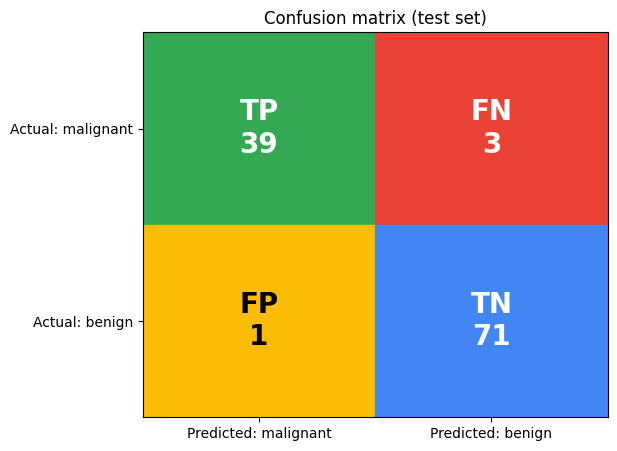

In [14]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred, labels=[1, 0])     # [[TP, FN], [FP, TN]]
tp, fn, fp, tn = cm.ravel()
print(f"TP = {tp}   FN = {fn}   FP = {fp}   TN = {tn}")

names  = [["TP", "FN"], ["FP", "TN"]]
colors = [["#34A853", "#EA4335"], ["#FBBC04", "#4285F4"]]
fig, ax = plt.subplots(figsize=(6, 5))
for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, color=colors[i][j]))
        ax.text(j + 0.5, 1.5 - i, f"{names[i][j]}\n{cm[i, j]}", ha="center", va="center",
                fontsize=20, fontweight="bold", color="white" if colors[i][j] != "#FBBC04" else "black")
ax.set_xlim(0, 2); ax.set_ylim(0, 2)
ax.set_xticks([0.5, 1.5]); ax.set_xticklabels(["Predicted: malignant", "Predicted: benign"])
ax.set_yticks([0.5, 1.5]); ax.set_yticklabels(["Actual: benign", "Actual: malignant"])
ax.set_title("Confusion matrix (test set)")
plt.show()

## 7.2 Accuracy, precision, recall, F1
- **Accuracy** = (TP+TN) / N: overall, how often is the model right?
- **Precision** = TP / (TP+FP): of the predicted malignant, how many truly are?
- **Recall** = TP / (TP+FN): of the real malignant, how many were found? *(watch it first for cancer)*
- **F1-score** = 2·P·R / (P+R): balance between precision and recall.

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
pd.DataFrame({"score": [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
                        recall_score(y_test, y_pred), f1_score(y_test, y_pred)]},
             index=["accuracy", "precision", "recall", "F1"])

,score
accuracy,0.9649
precision,0.9750
recall,0.9286
F1,0.9512


## 7.3 ROC curve and AUC
For every threshold we get one point:
- **TPR** (True Positive Rate) = recall = TP / (TP+FN)
- **FPR** (False Positive Rate) = FP / (FP+TN)

The **AUC** (area under the curve) is 0.5 for a random model and 1.0 for a perfect one. It does not depend on a single threshold.

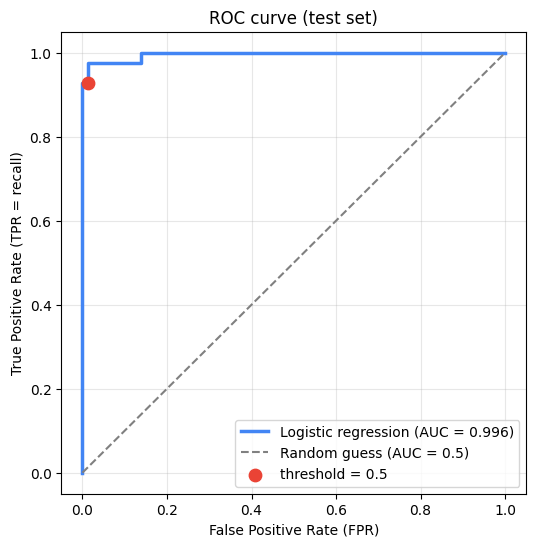

AUC = 0.9960


In [16]:

from sklearn.metrics import (roc_curve, roc_auc_score)
fpr, tpr, thresholds = roc_curve(y_test, proba)
auc_value = roc_auc_score(y_test, proba)

# Our current threshold (0.5) is one point of the curve
tpr_05 = tp / (tp + fn)
fpr_05 = fp / (fp + tn)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="#4285F4", linewidth=2.5, label=f"Logistic regression (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess (AUC = 0.5)")
plt.scatter([fpr_05], [tpr_05], color="#EA4335", s=80, zorder=5, label="threshold = 0.5")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR = recall)")
plt.title("ROC curve (test set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()
print(f"AUC = {auc_value:.4f}")

---
# Step 8 · Interpret coefficients
Each feature has one weight `wj`. Because the features are standardized, the weights are comparable:
- `wj > 0`: a larger value of the feature pushes **z up** -> toward **malignant**.
- `wj < 0`: a larger value pushes **z down** -> toward **benign**.
- The larger |wj|, the more important the feature in the model.

In [17]:
coef_table = pd.DataFrame({
    "weight (w)": model.coef_[0],
    "pushes toward": np.where(model.coef_[0] > 0, "malignant", "benign"),
}, index=X.columns).sort_values("weight (w)", ascending=False)

print("Bias (intercept) w0 =", round(model.intercept_[0], 4))
coef_table      # all 30 weights, from most 'malignant' to most 'benign'

Bias (intercept) w0 = -0.243


,weight (w),pushes toward
worst texture,1.4341,malignant
radius error,1.2333,malignant
worst symmetry,1.0613,malignant
mean concave points,0.9528,malignant
worst concavity,0.9114,malignant
area error,0.9090,malignant
worst area,0.9005,malignant
worst radius,0.8970,malignant
mean concavity,0.7823,malignant
perimeter error,0.7483,malignant
